In [ ]:
%pip install nilearn "pandas==2.2.3" "requests==2.32.4"

Volume shape: (197, 233, 189)
Voxel size (mm): (np.float32(1.0), np.float32(1.0), np.float32(1.0))


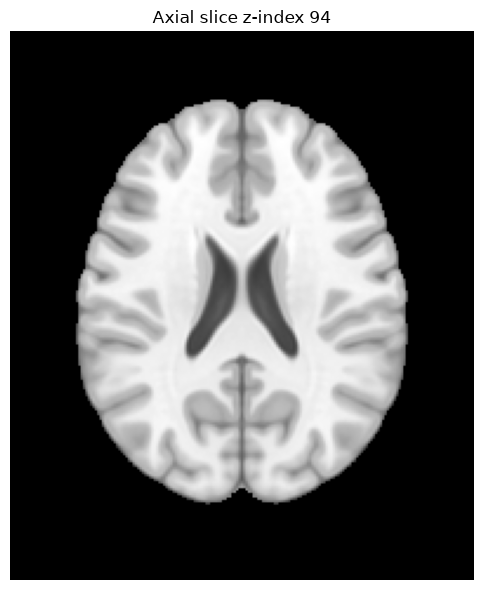

Slice shape: (197, 233) | min/max: 0.0 0.9215686321258545


In [1]:

"""
Load and display an axial MRI slice of the brain from a public dataset.
 
Requirements:
    pip install nilearn nibabel matplotlib numpy
 
Two sources are supported:
  - "mni"   : MNI152 T1 template (ships with nilearn, no download needed)
  - "haxby" : a real subject's T1 anatomical scan from the Haxby 2001 dataset
              (downloaded automatically by nilearn on first use, ~300 MB)
"""
 
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from nilearn import datasets
 
 
def load_volume(source="mni"):
    """Return a NIfTI image reoriented to RAS (x=left→right, y=back→front, z=bottom→top)."""
    if source == "mni":
        img = datasets.load_mni152_template(resolution=1)
    elif source == "haxby":
        haxby = datasets.fetch_haxby(subjects=[1])
        img = nib.load(haxby.anat[0])
    else:
        raise ValueError("source must be 'mni' or 'haxby'")
 
    # Reorient so the third axis is always inferior→superior (axial slices)
    return nib.as_closest_canonical(img)
 
 
def get_axial_slice(img, z_index=None):
    """Extract a 2D axial slice. Defaults to the middle slice."""
    data = img.get_fdata()
    if z_index is None:
        z_index = data.shape[2] // 2
    return data[:, :, z_index], z_index
 
 
def get_axial_slice_mm(img, z_mm):
    """Extract the axial slice closest to a world coordinate z (in mm)."""
    inv = np.linalg.inv(img.affine)
    _, _, k = nib.affines.apply_affine(inv, [0, 0, z_mm])
    k = int(round(k))
    k = int(np.clip(k, 0, img.shape[2] - 1))
    return get_axial_slice(img, k)
 
 
if __name__ == "__main__":
    img = load_volume("mni")          # change to "haxby" for a real subject scan
    print("Volume shape:", img.shape)
    print("Voxel size (mm):", img.header.get_zooms()[:3])
 
    slice_2d, k = get_axial_slice(img)            # middle slice
    # slice_2d, k = get_axial_slice_mm(img, 10)   # or pick by mm (e.g. z = +10 mm)
 
    # Rotate so anterior is up; shown in neurological convention (left on left)
    plt.figure(figsize=(6, 6))
    plt.imshow(np.rot90(slice_2d), cmap="gray")
    plt.title(f"Axial slice z-index {k}")
    plt.axis("off")
    plt.tight_layout()
    plt.show()
 
    # The raw 2D array is ready for further processing:
    print("Slice shape:", slice_2d.shape, "| min/max:", slice_2d.min(), slice_2d.max())
    

Max reconstruction error: 1.9984014443252818e-15


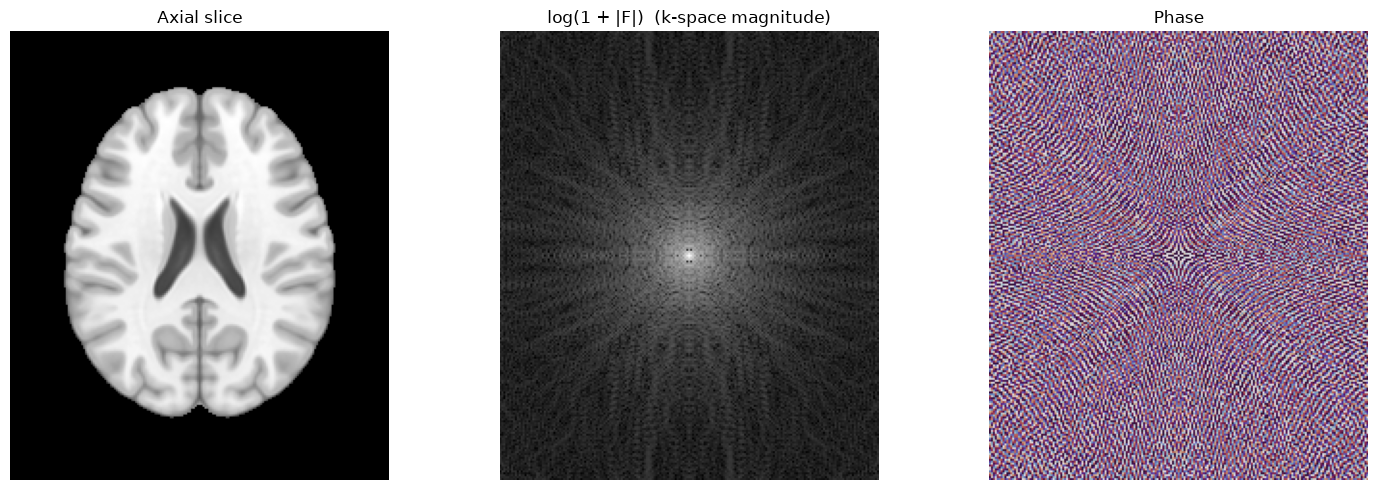

In [2]:
import numpy as np
import matplotlib.pyplot as plt

img2d = np.rot90(slice_2d)                 # same orientation as the display

# 2D FFT, with the zero frequency (DC) moved to the centre
F = np.fft.fftshift(np.fft.fft2(img2d))

magnitude = np.abs(F)
phase = np.angle(F)
log_mag = np.log1p(magnitude)              # log scale, otherwise only the DC spike is visible

# Sanity check: the inverse FFT should give back the original image
recon = np.real(np.fft.ifft2(np.fft.ifftshift(F)))
print("Max reconstruction error:", np.abs(recon - img2d).max())

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img2d, cmap="gray")
axes[0].set_title("Axial slice")
axes[1].imshow(log_mag, cmap="gray")
axes[1].set_title("log(1 + |F|)  (k-space magnitude)")
axes[2].imshow(phase, cmap="twilight")
axes[2].set_title("Phase")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

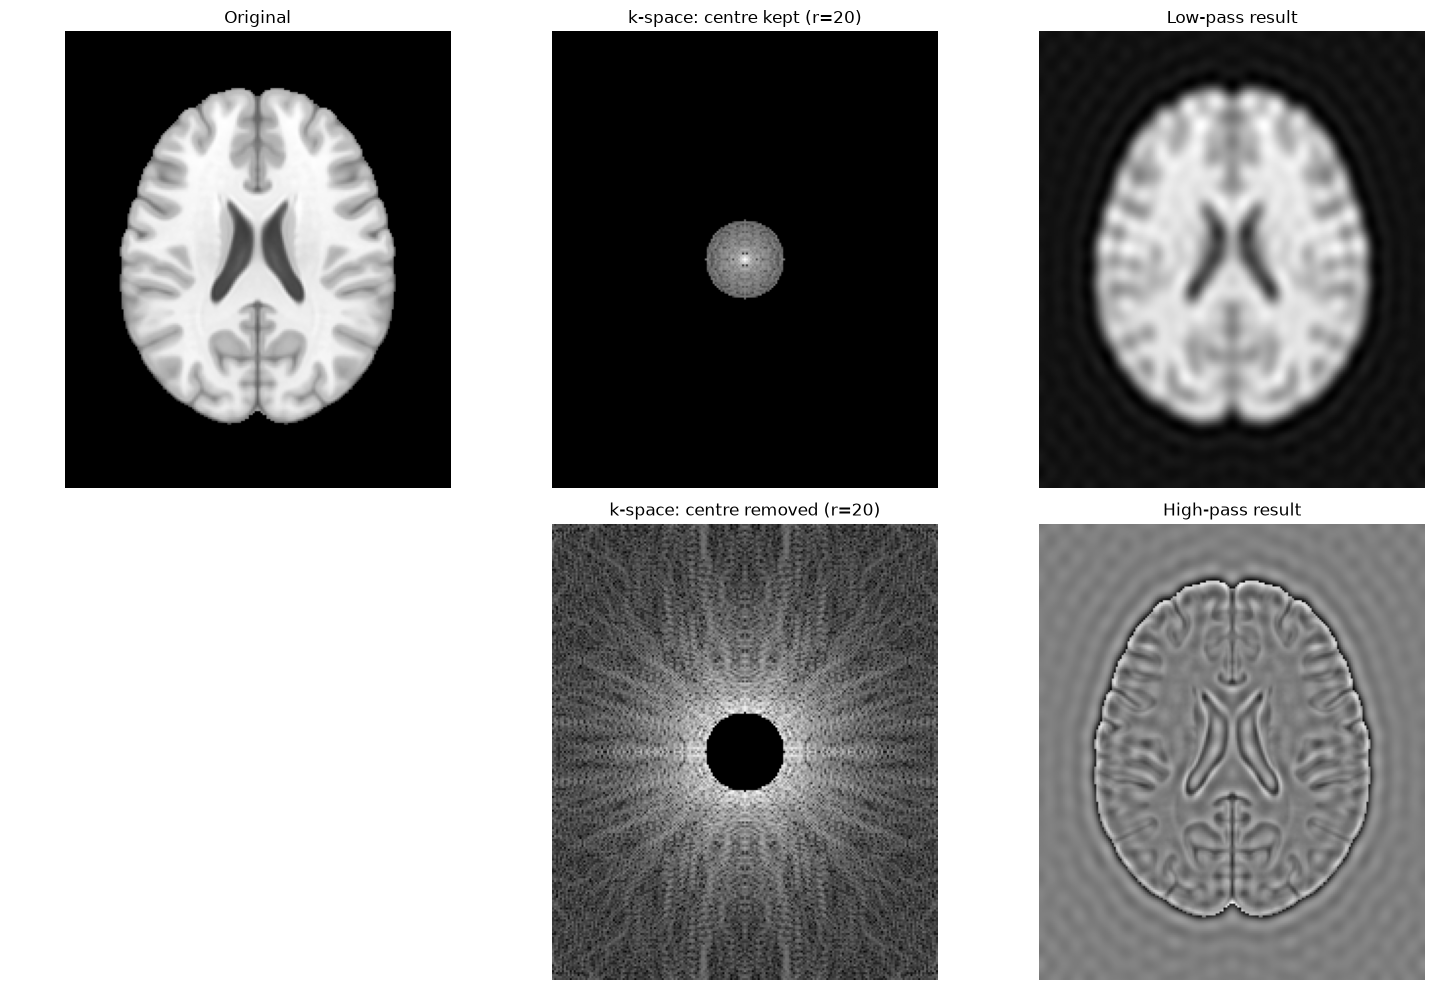

In [3]:
radius = 20                                     # circle radius in pixels of k-space

rows, cols = F.shape
cy, cx = rows // 2, cols // 2                   # centre of the shifted spectrum
y, x = np.ogrid[:rows, :cols]
circle = (y - cy) ** 2 + (x - cx) ** 2 <= radius ** 2

F_low = F * circle                              # keep only the centre
F_high = F * ~circle                            # remove the centre

img_low = np.real(np.fft.ifft2(np.fft.ifftshift(F_low)))
img_high = np.real(np.fft.ifft2(np.fft.ifftshift(F_high)))

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes[0, 0].imshow(img2d, cmap="gray")
axes[0, 0].set_title("Original")
axes[0, 1].imshow(np.log1p(np.abs(F_low)), cmap="gray")
axes[0, 1].set_title(f"k-space: centre kept (r={radius})")
axes[0, 2].imshow(img_low, cmap="gray")
axes[0, 2].set_title("Low-pass result")
axes[1, 0].axis("off")
axes[1, 1].imshow(np.log1p(np.abs(F_high)), cmap="gray")
axes[1, 1].set_title(f"k-space: centre removed (r={radius})")
axes[1, 2].imshow(img_high, cmap="gray")
axes[1, 2].set_title("High-pass result")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

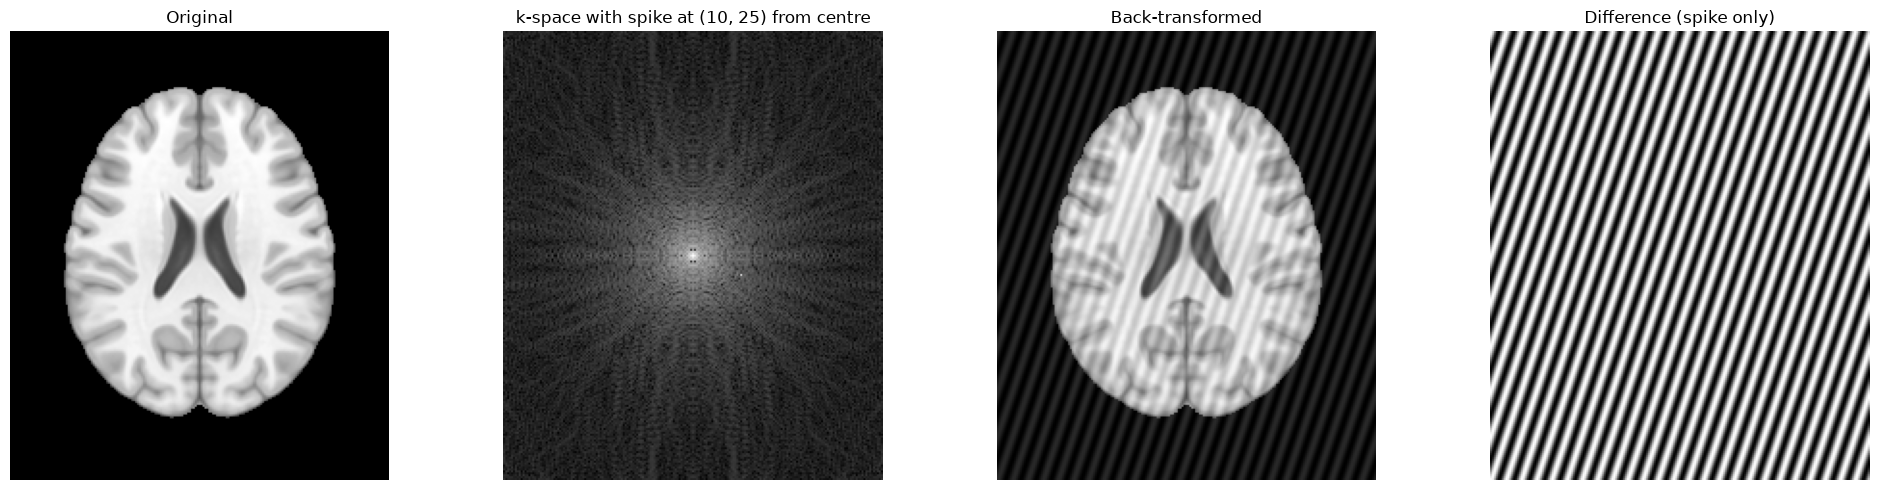

In [ ]:
dy, dx = 10, 25                          # offset of the spike from the centre, in pixels
strength = 0.3                           # spike brightness relative to the DC (centre) value

F_spike = F.copy()
F_spike[cy + dy, cx + dx] += strength * np.abs(F).max()

img_spike = np.real(np.fft.ifft2(np.fft.ifftshift(F_spike)))
stripes = img_spike - img2d              # what the spike added on its own

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(img2d, cmap="gray")
axes[0].set_title("Original")
axes[1].imshow(np.log1p(np.abs(F_spike)), cmap="gray")
axes[1].plot(cx + dx, cy + dy, "r+", markersize=15)
axes[1].set_title(f"k-space with spike at ({dy}, {dx}) from centre")
axes[2].imshow(img_spike, cmap="gray")
axes[2].set_title("Back-transformed")
axes[3].imshow(stripes, cmap="gray")
axes[3].set_title("Difference (spike only)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

Original image:      (233, 197)
Cropped k-space:     (58, 48)
Without zero-fill:   (58, 48)
With zero-fill:      (233, 197)


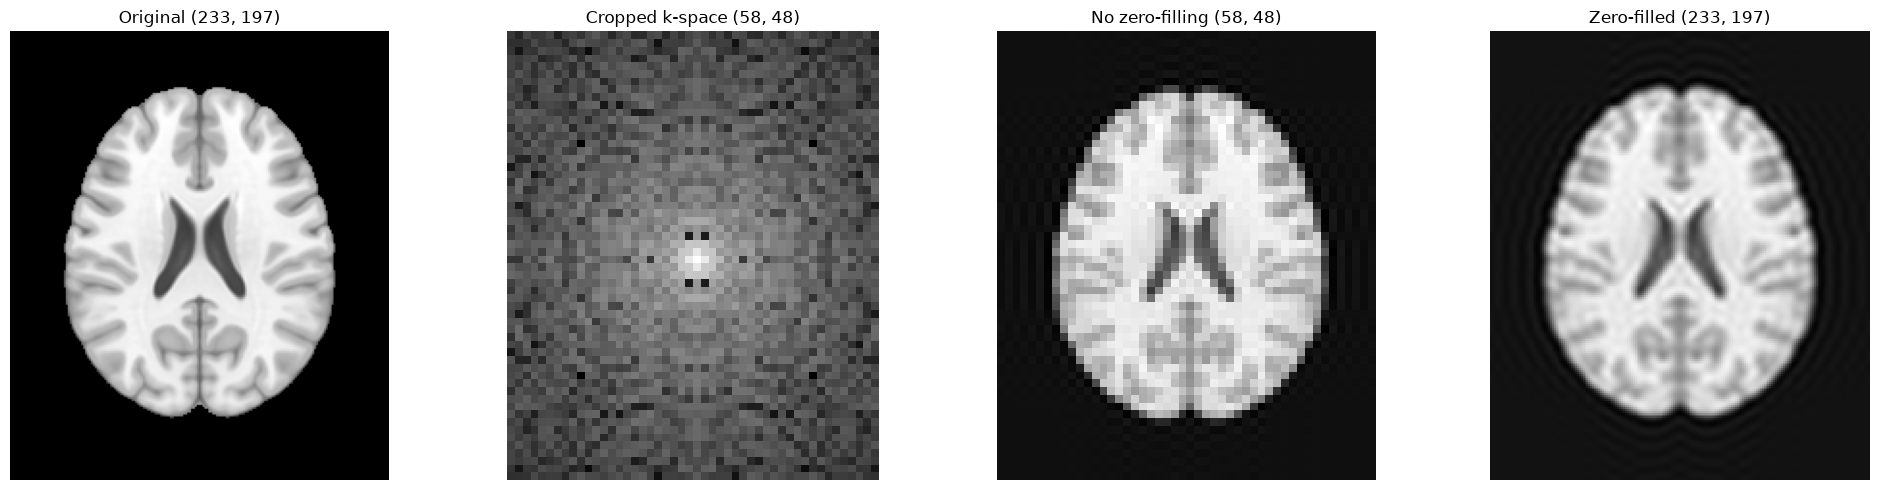

In [6]:
keep = 0.25                                   # fraction of k-space kept along each axis
h = int(rows * keep / 2)                      # half-height of the kept region
w = int(cols * keep / 2)                      # half-width

# Crop the centre of k-space
F_crop = F[cy - h:cy + h, cx - w:cx + w]

# 1) Without zero-filling: inverse FFT of the small array -> small image
img_small = np.real(np.fft.ifft2(np.fft.ifftshift(F_crop)))
img_small *= F_crop.size / F.size             # undo the size-dependent ifft scaling

# 2) With zero-filling: put the crop back into a full-size array of zeros
F_zf = np.zeros_like(F)
F_zf[cy - h:cy + h, cx - w:cx + w] = F_crop
img_zf = np.real(np.fft.ifft2(np.fft.ifftshift(F_zf)))

print("Original image:     ", img2d.shape)
print("Cropped k-space:    ", F_crop.shape)
print("Without zero-fill:  ", img_small.shape)
print("With zero-fill:     ", img_zf.shape)

extent = [0, cols, rows, 0]                   # show all images at the same physical size
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(img2d, cmap="gray", extent=extent)
axes[0].set_title(f"Original {img2d.shape}")
axes[1].imshow(np.log1p(np.abs(F_crop)), cmap="gray")
axes[1].set_title(f"Cropped k-space {F_crop.shape}")
axes[2].imshow(img_small, cmap="gray", extent=extent, interpolation="nearest")
axes[2].set_title(f"No zero-filling {img_small.shape}")
axes[3].imshow(img_zf, cmap="gray", extent=extent, interpolation="nearest")
axes[3].set_title(f"Zero-filled {img_zf.shape}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

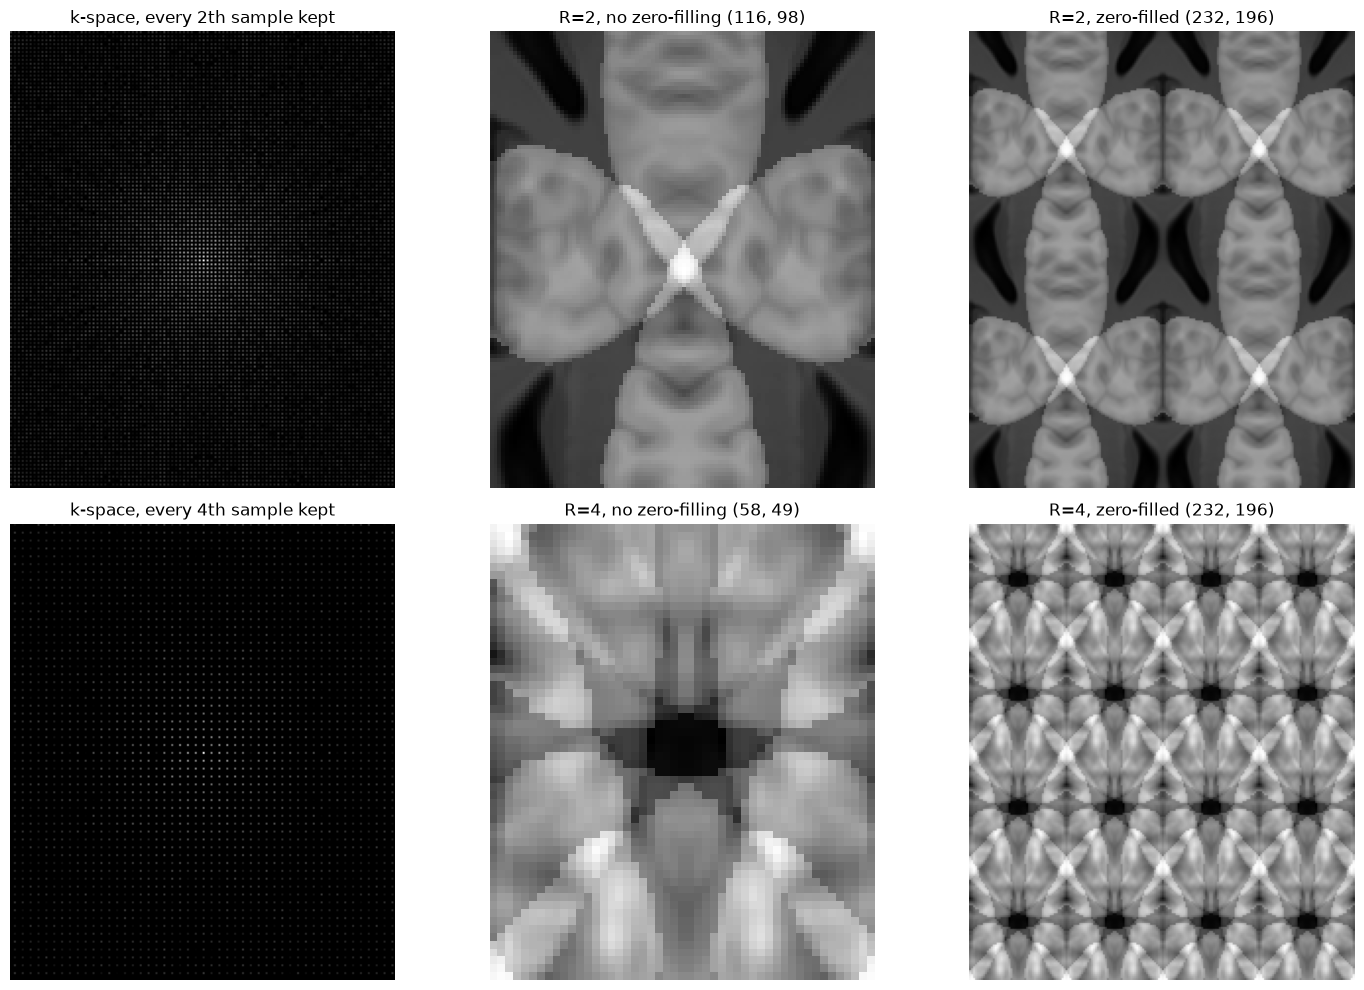

In [7]:
# Trim the image so its sides are divisible by 4 (the MNI slice is 233 x 197 pixels);
# this makes the aliased copies fold exactly. Only empty background is removed.
r_even = img2d.shape[0] - img2d.shape[0] % 4
c_even = img2d.shape[1] - img2d.shape[1] % 4
img_even = img2d[:r_even, :c_even]

Fu = np.fft.fft2(img_even)                    # unshifted: zero frequency at [0, 0]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for row, R in enumerate([2, 4]):
    # 1) Without zero-filling: keep every R-th sample -> smaller array, smaller image
    G = Fu[::R, ::R]
    img_dec = np.real(np.fft.ifft2(G))

    # 2) With zero-filling: full-size array, skipped samples set to zero
    mask = np.zeros(Fu.shape, dtype=bool)
    mask[::R, ::R] = True
    img_zf = np.real(np.fft.ifft2(Fu * mask))

    axes[row, 0].imshow(np.log1p(np.abs(np.fft.fftshift(Fu * mask))), cmap="gray")
    axes[row, 0].set_title(f"k-space, every {R}th sample kept")
    axes[row, 1].imshow(img_dec, cmap="gray")
    axes[row, 1].set_title(f"R={R}, no zero-filling {img_dec.shape}")
    axes[row, 2].imshow(img_zf, cmap="gray")
    axes[row, 2].set_title(f"R={R}, zero-filled {img_zf.shape}")

for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()


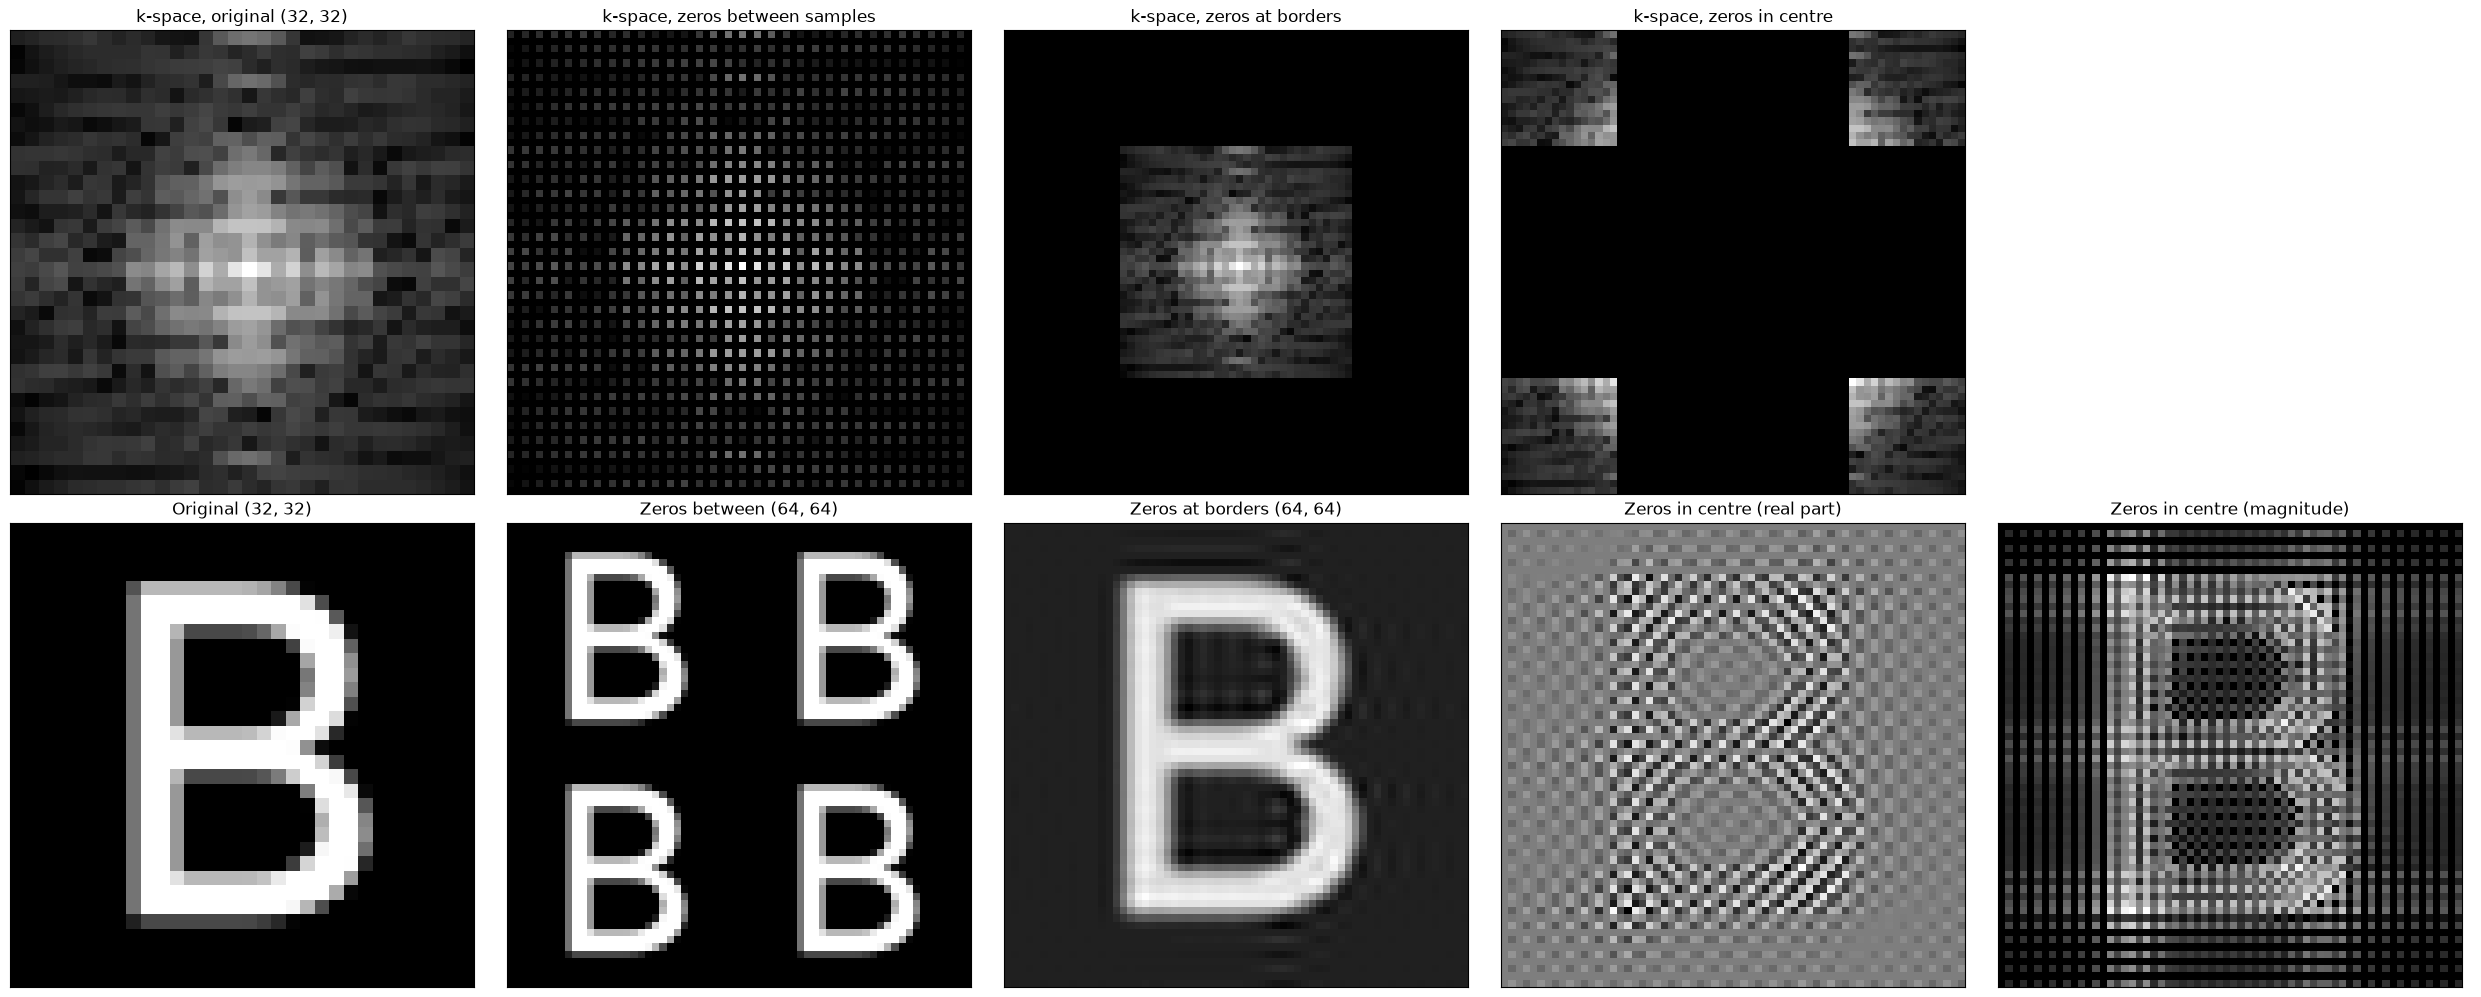

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# --- Make a 128 x 128 image of the letter zeta --------------------------------
N = 32
fig = plt.figure(figsize=(1, 1), dpi=N)
#fig.text(0.5, 0.5, "ζ", fontsize=90, ha="center", va="center")
fig.text(0.5, 0.4, "B", fontsize=70, ha="center", va="center")
fig.canvas.draw()
zeta = 1 - np.asarray(fig.canvas.buffer_rgba())[..., 0] / 255.0   # white letter on black
plt.close(fig)

K = np.fft.fft2(zeta)              # unshifted spectrum, zero frequency at [0, 0]
S = np.fft.fftshift(K)             # shifted spectrum, zero frequency at the centre
M = 2 * N                          # every version is zero-filled to twice the size
h = N // 2

# A) Zeros between the samples: every other k-space point is zero
K_between = np.zeros((M, M), complex)
K_between[::2, ::2] = K
img_between = np.fft.ifft2(K_between) * 4

# B) Zeros at the borders: the original spectrum sits in the centre
S_border = np.zeros((M, M), complex)
S_border[h:h + N, h:h + N] = S
img_border = np.fft.ifft2(np.fft.ifftshift(S_border)) * 4

# C) Zeros in the centre: the four quadrants of the spectrum are pushed into the corners
S_centre = np.zeros((M, M), complex)
S_centre[:h, :h], S_centre[:h, -h:] = S[:h, :h], S[:h, h:]
S_centre[-h:, :h], S_centre[-h:, -h:] = S[h:, :h], S[h:, h:]
img_centre = np.fft.ifft2(np.fft.ifftshift(S_centre)) * 4

# --- Plot ------------------------------------------------------------------------
def logmag(F_shifted):
    return np.log1p(np.abs(F_shifted))

fig, axes = plt.subplots(2, 5, figsize=(25, 10))
axes[0, 0].imshow(logmag(S), cmap="gray");                         axes[0, 0].set_title(f"k-space, original {S.shape}")
axes[0, 1].imshow(logmag(np.fft.fftshift(K_between)), cmap="gray"); axes[0, 1].set_title("k-space, zeros between samples")
axes[0, 2].imshow(logmag(S_border), cmap="gray");                  axes[0, 2].set_title("k-space, zeros at borders")
axes[0, 3].imshow(logmag(S_centre), cmap="gray");                  axes[0, 3].set_title("k-space, zeros in centre")
axes[0, 4].axis("off")

axes[1, 0].imshow(zeta, cmap="gray");              axes[1, 0].set_title(f"Original {zeta.shape}")
axes[1, 1].imshow(img_between.real, cmap="gray");  axes[1, 1].set_title(f"Zeros between {img_between.shape}")
axes[1, 2].imshow(img_border.real, cmap="gray");   axes[1, 2].set_title(f"Zeros at borders {img_border.shape}")
axes[1, 3].imshow(img_centre.real, cmap="gray");   axes[1, 3].set_title("Zeros in centre (real part)")
axes[1, 4].imshow(np.abs(img_centre), cmap="gray"); axes[1, 4].set_title("Zeros in centre (magnitude)")

for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

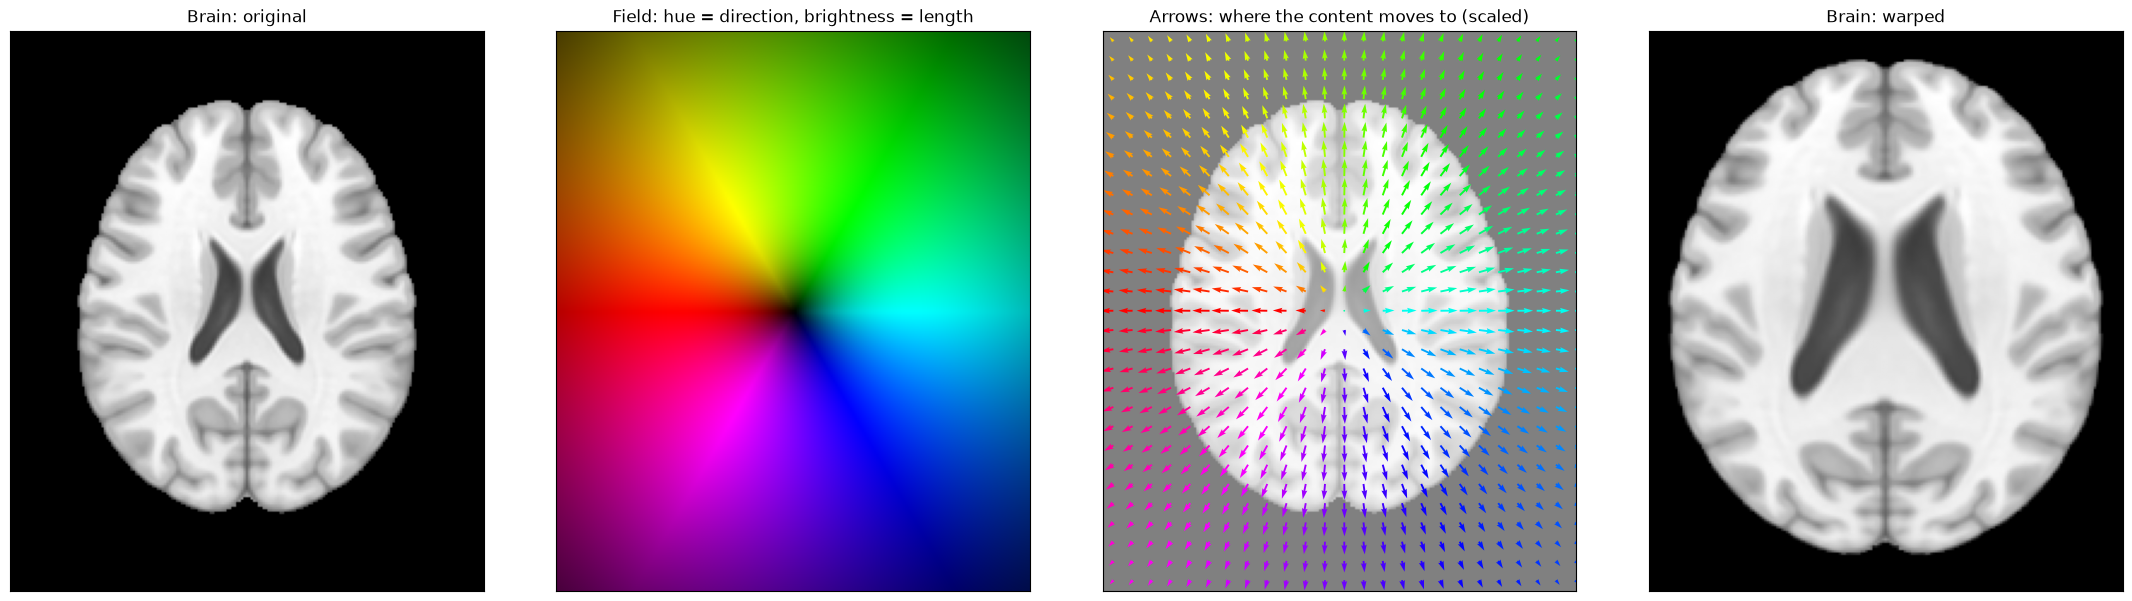

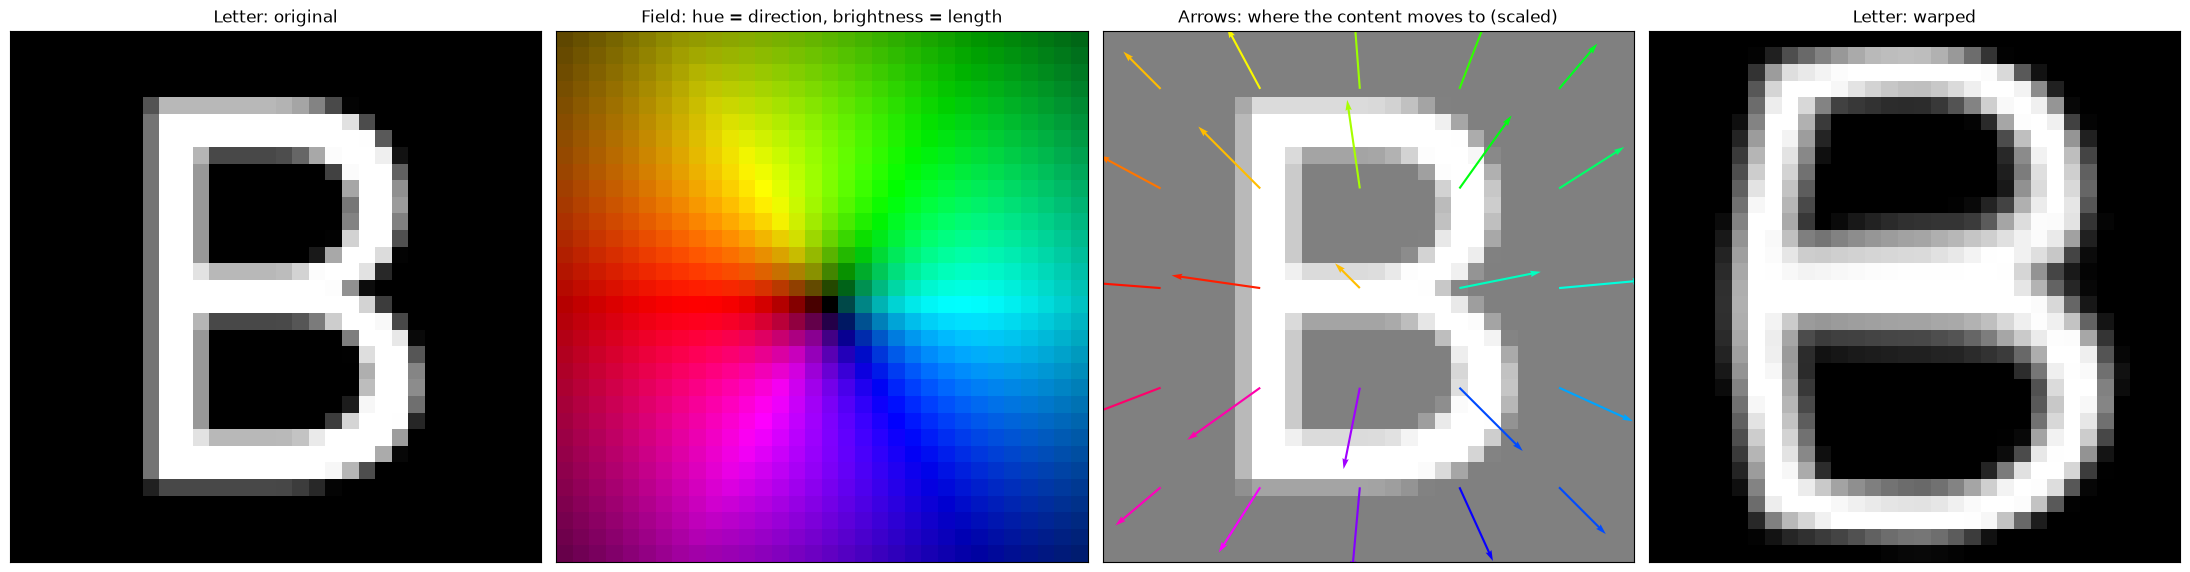

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import hsv_to_rgb
from scipy.ndimage import map_coordinates


def lens_field(shape, center=None, sigma=None, strength=0.5):
    """Smooth spherical-lens distortion with a Gaussian falloff.

    A pixel at output radius r takes its value from radius
        r_src = r * (1 - strength * exp(-(r / sigma)^2))
    strength in (0, 1): magnification at the centre is 1 / (1 - strength).
    Negative strength shrinks the centre instead (pinch).

    Returns
      back = (dy, dx): for each output pixel, where it samples the input (used for warping)
      fwd  = (dy, dx): for each input pixel, where its content ends up (used for display)
    """
    rows, cols = shape
    cy, cx = center if center is not None else (rows / 2, cols / 2)
    sigma = sigma if sigma is not None else 0.5 * min(rows, cols)

    y, x = np.mgrid[:rows, :cols].astype(float)
    ry, rx = y - cy, x - cx
    r = np.hypot(ry, rx)

    def r_src_of(r_out):
        return r_out * (1 - strength * np.exp(-(r_out / sigma) ** 2))

    # Backward map (exact)
    with np.errstate(invalid="ignore", divide="ignore"):
        s_back = np.where(r > 0, r_src_of(r) / r, 1.0)
    back = (ry * s_back - ry, rx * s_back - rx)

    # Forward map: invert the radial mapping numerically (it is monotonic)
    r_table = np.linspace(0, 2 * r.max() + 1, 4000)
    r_out = np.interp(r, r_src_of(r_table), r_table)
    with np.errstate(invalid="ignore", divide="ignore"):
        s_fwd = np.where(r > 0, r_out / r, 1.0)
    fwd = (ry * s_fwd - ry, rx * s_fwd - rx)
    return back, fwd


def warp(image, dy, dx):
    """Backward warp: output(y, x) = input(y + dy, x + dx), bilinear interpolation."""
    y, x = np.mgrid[:image.shape[0], :image.shape[1]].astype(float)
    return map_coordinates(image, [y + dy, x + dx], order=1, mode="constant", cval=0.0)


def field_to_rgb(dy, dx):
    """Colour-code a vector field: hue = direction, brightness = length."""
    angle = np.arctan2(dy, dx)
    mag = np.hypot(dy, dx)
    hsv = np.stack([(angle + np.pi) / (2 * np.pi),
                    np.ones_like(mag),
                    mag / (mag.max() + 1e-12)], axis=-1)
    return hsv_to_rgb(hsv)


def show_field_and_warp(image, back, fwd, title, step=8):
    warped = warp(image, *back)
    dy, dx = fwd                                      # display how the content moves
    rows, cols = image.shape
    ys, xs = np.mgrid[step // 2:rows:step, step // 2:cols:step]
    u, v = dy[ys, xs], dx[ys, xs]
    hue = (np.arctan2(u, v) + np.pi) / (2 * np.pi)

    fig, axes = plt.subplots(1, 4, figsize=(22, 6))
    axes[0].imshow(image, cmap="gray")
    axes[0].set_title(f"{title}: original")

    axes[1].imshow(field_to_rgb(dy, dx))
    axes[1].set_title("Field: hue = direction, brightness = length")

    axes[2].imshow(image, cmap="gray", alpha=0.5)
    arrow_scale = np.hypot(u, v).max() / (0.9 * step)  # longest arrow just under the grid spacing
    axes[2].quiver(xs, ys, v, u, hue, cmap="hsv", clim=(0, 1),
                   angles="xy", scale_units="xy", scale=arrow_scale, width=0.004)
    axes[2].set_title("Arrows: where the content moves to (scaled)")

    axes[3].imshow(warped, cmap="gray")
    axes[3].set_title(f"{title}: warped")
    for ax in axes:
        ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout()
    plt.show()
    return warped


# Brain slice
back, fwd = lens_field(img2d.shape, strength=0.5)
brain_warped = show_field_and_warp(img2d, back, fwd, "Brain")

# Letter from the intermission cell
back_l, fwd_l = lens_field(zeta.shape, strength=0.5)
letter_warped = show_field_and_warp(zeta, back_l, fwd_l, "Letter", step=6)

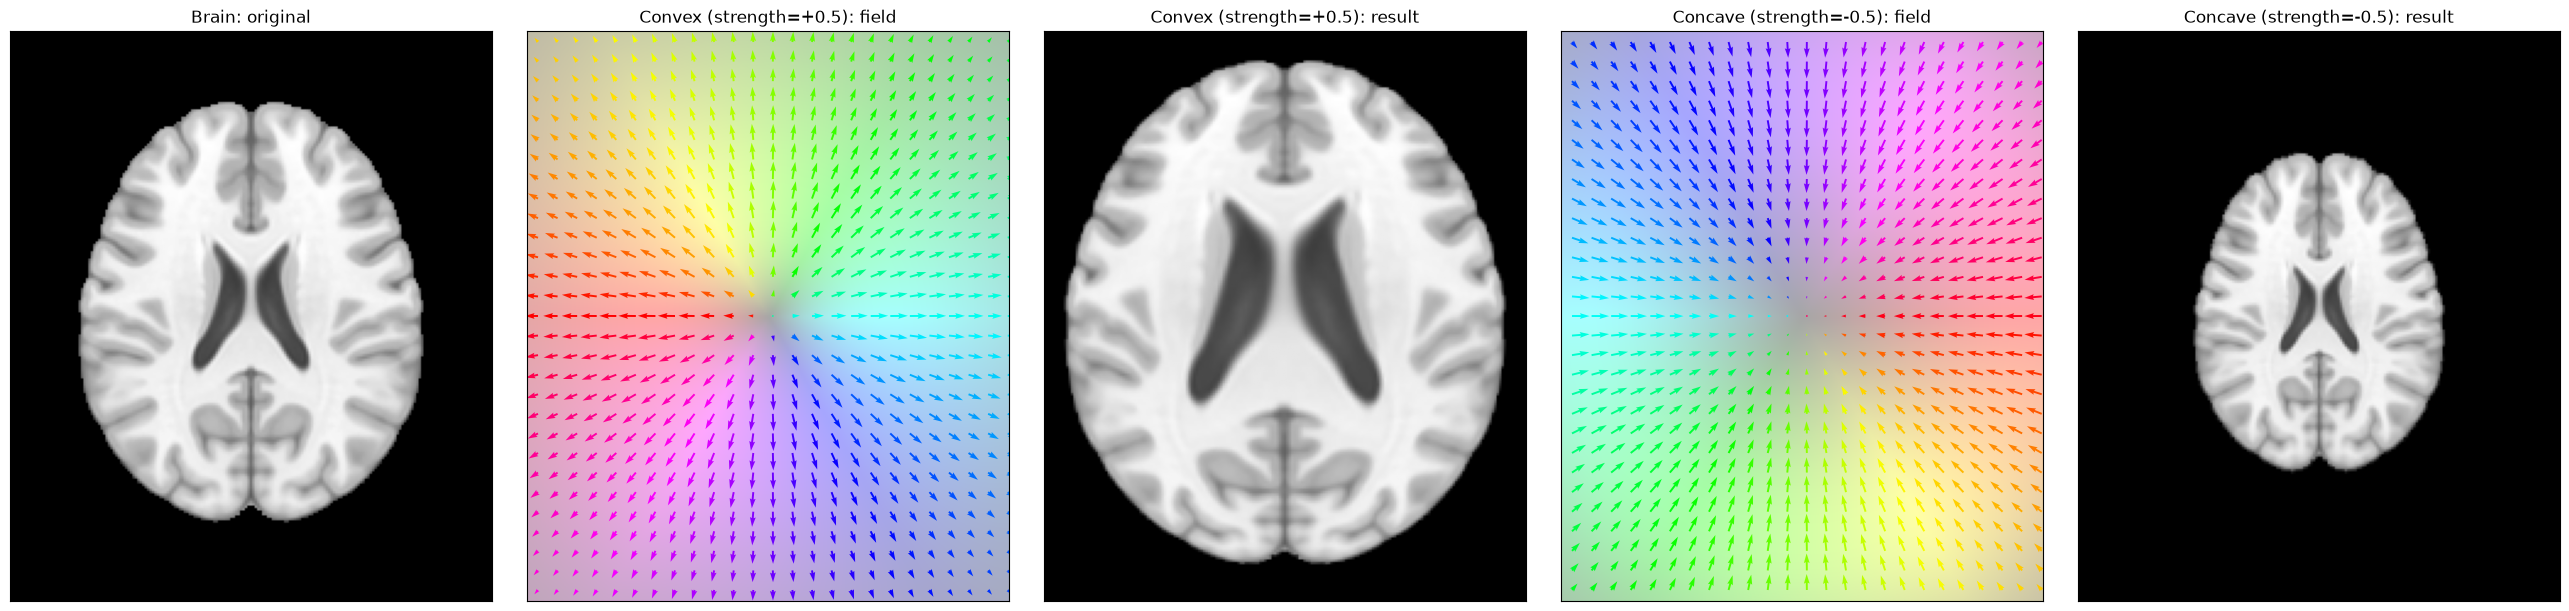

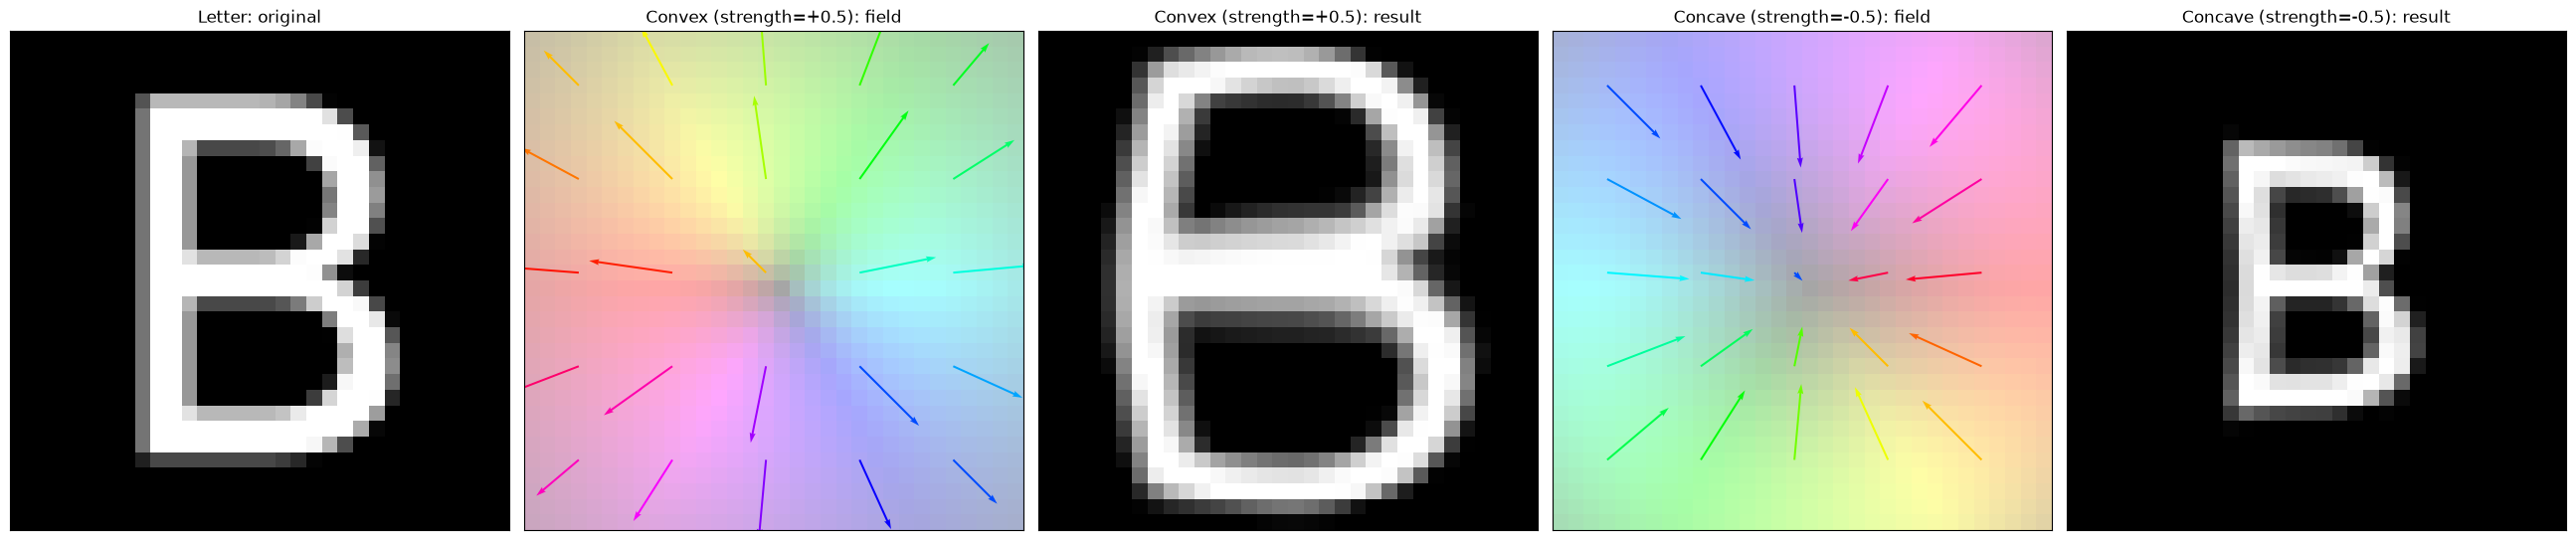

In [18]:
def show_lens_comparison(image, title, strength=0.5, step=8, sigma=None):
    """Original, convex lens (magnifying) and concave lens (minifying) side by side."""
    rows, cols = image.shape
    ys, xs = np.mgrid[step // 2:rows:step, step // 2:cols:step]

    lenses = {
        f"Convex (strength=+{strength})": lens_field(image.shape, strength=+strength, sigma=sigma),
        f"Concave (strength=-{strength})": lens_field(image.shape, strength=-strength, sigma=sigma),
    }

    fig, axes = plt.subplots(1, 5, figsize=(26, 6))
    axes[0].imshow(image, cmap="gray")
    axes[0].set_title(f"{title}: original")

    for i, (name, (back, fwd)) in enumerate(lenses.items()):
        dy, dx = fwd
        u, v = dy[ys, xs], dx[ys, xs]
        hue = (np.arctan2(u, v) + np.pi) / (2 * np.pi)
        arrow_scale = np.hypot(u, v).max() / (0.9 * step)

        ax_f, ax_w = axes[1 + 2 * i], axes[2 + 2 * i]
        ax_f.imshow(field_to_rgb(dy, dx), alpha=0.35)
        ax_f.quiver(xs, ys, v, u, hue, cmap="hsv", clim=(0, 1),
                    angles="xy", scale_units="xy", scale=arrow_scale, width=0.004)
        ax_f.set_title(f"{name}: field")
        ax_w.imshow(warp(image, *back), cmap="gray")
        ax_w.set_title(f"{name}: result")

    for ax in axes:
        ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout()
    plt.show()


show_lens_comparison(img2d, "Brain", strength=0.5)
show_lens_comparison(zeta, "Letter", strength=0.5, step=6)

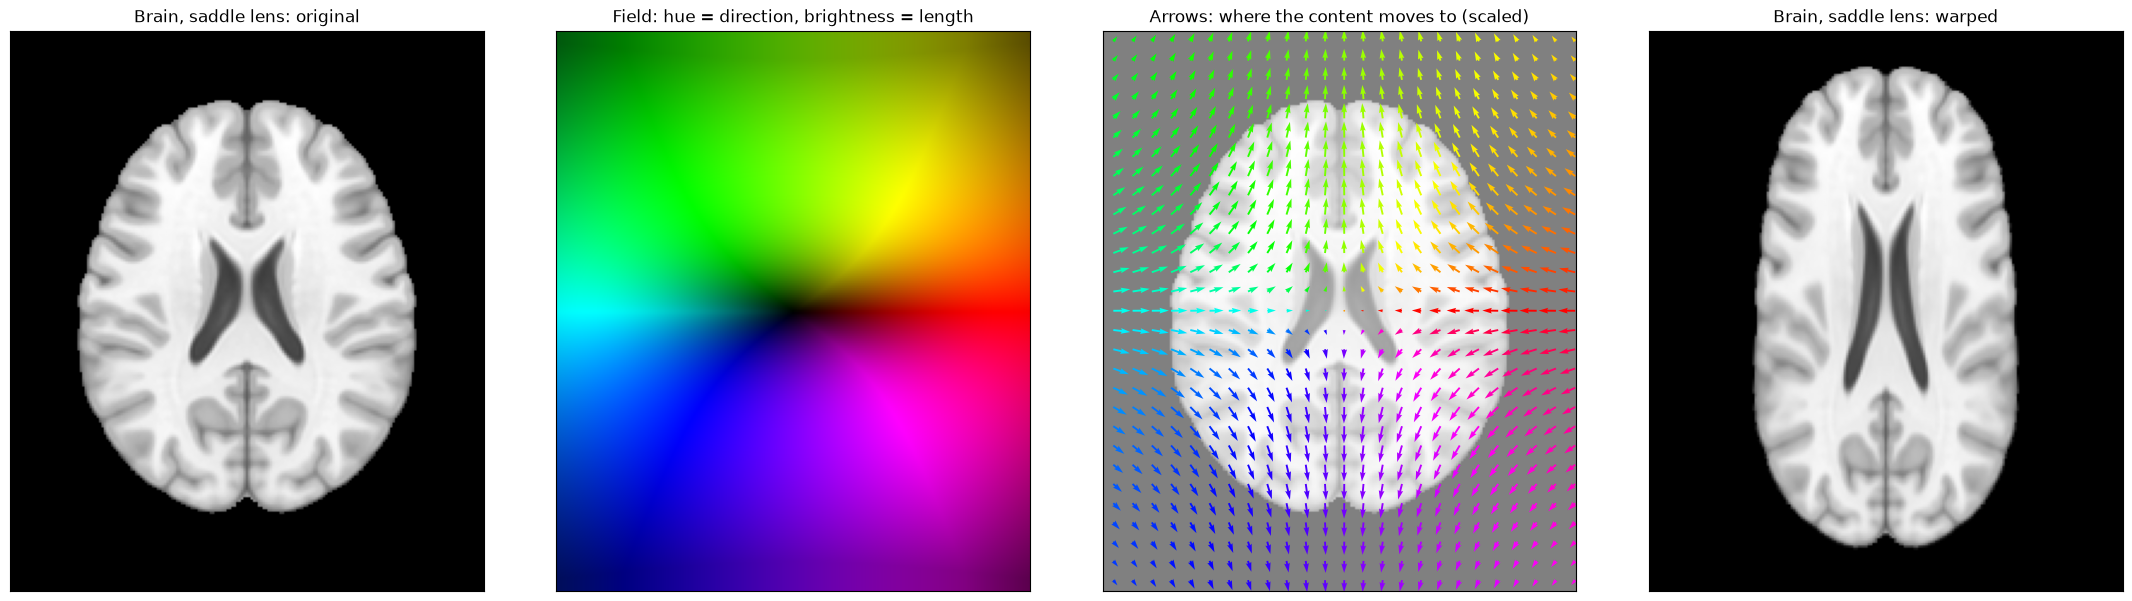

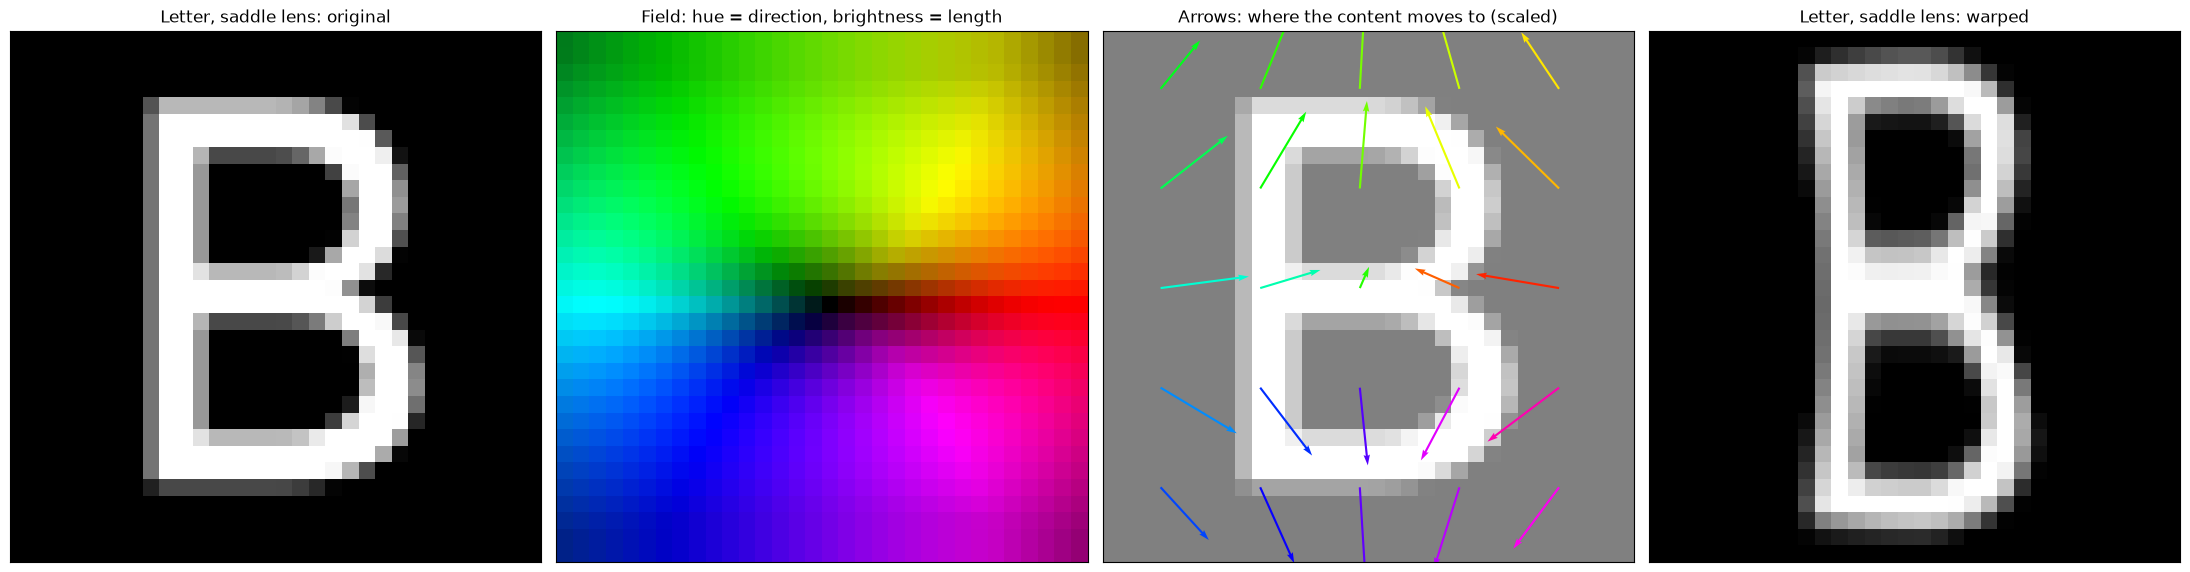

In [19]:
def invert_field(back, iterations=50):
    """Forward field from a backward field by fixed-point iteration.

    Solves o + back(o) = s for every input position s; fwd = o - s.
    Converges as long as the field is smooth (no folding).
    """
    dy_b, dx_b = back
    rows, cols = dy_b.shape
    y, x = np.mgrid[:rows, :cols].astype(float)
    oy, ox = y.copy(), x.copy()
    for _ in range(iterations):
        by = map_coordinates(dy_b, [oy, ox], order=1, mode="nearest")
        bx = map_coordinates(dx_b, [oy, ox], order=1, mode="nearest")
        oy, ox = y - by, x - bx
    return oy - y, ox - x


def saddle_field(shape, center=None, sigma=None, strength_y=0.4, strength_x=-0.4):
    """Saddle lens: convex (magnifying) along y, concave (shrinking) along x.

    y_src = y * (1 - strength_y * g),  x_src = x * (1 - strength_x * g)
    with a smooth Gaussian envelope g = exp(-(r / sigma)^2).
    Positive strength magnifies along that axis, negative strength shrinks.
    """
    rows, cols = shape
    cy, cx = center if center is not None else (rows / 2, cols / 2)
    sigma = sigma if sigma is not None else 0.5 * min(rows, cols)

    y, x = np.mgrid[:rows, :cols].astype(float)
    ry, rx = y - cy, x - cx
    g = np.exp(-(ry ** 2 + rx ** 2) / sigma ** 2)

    back = (-strength_y * g * ry, -strength_x * g * rx)
    fwd = invert_field(back)
    return back, fwd


# Brain slice
back_s, fwd_s = saddle_field(img2d.shape, strength_y=0.4, strength_x=-0.4)
brain_saddle = show_field_and_warp(img2d, back_s, fwd_s, "Brain, saddle lens")

# Letter
back_sl, fwd_sl = saddle_field(zeta.shape, strength_y=0.4, strength_x=-0.4)
letter_saddle = show_field_and_warp(zeta, back_sl, fwd_sl, "Letter, saddle lens", step=6)